# Forecasting European electricity prices: an investigation

A guided recap of the data, pipeline changes and completed experiments. **MAE is an error in EUR/MWh, not classification accuracy.** Lower is better.

Read top to bottom for the project story; edit the next cell to investigate a country and validation week. This notebook fits no models and downloads no data. Published test scores are exploratory: that period has been inspected repeatedly.

**Contents:** 1. Data and timing · 2. Models and pipeline · 3. Competitive baselines · 4. Graphs, features and histories · 5. Airport observations · 6. Country investigations · 7. Conclusions and appendices


In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "epgnn").is_dir())
sys.path.insert(0, str(ROOT))
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.dataset as ds
from IPython.display import display, Markdown, HTML
from epgnn.reporting.investigation import Report, heatmap, plot_window
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 12)
report = Report(ROOT)


In [2]:
# Editable investigation parameters. Detailed outcomes stay in validation.
ZONES = ["FR", "DE_LU", "BE"]
COUNTRIES = ["FR", "DE_LU", "BE", "NL", "AT", "ES", "PT", "CZ", "CH", "NO", "IT"]
START = "2024-07-08T00:00:00+02:00"
END = "2024-07-15T00:00:00+02:00"
SEED = 224  # Illustrative seed, not a selected best seed.
MODELS = ["Per-zone XGBoost", "Pooled XGBoost", "MLP", "GAT"]
LOAD_LOCAL_DETAILS = True
display(pd.Series({"Markets": ", ".join(ZONES), "Validation window": START + " to " + END, "Illustrative seed": SEED, "Models": ", ".join(MODELS), "Local details": LOAD_LOCAL_DETAILS}).to_frame("Report selections"))


,Report selections
Markets,"FR, DE_LU, BE"
Validation window,2024-07-08T00:00:00+02:00 to 2024-07-15T00:00:...
Illustrative seed,224
Models,"Per-zone XGBoost, Pooled XGBoost, MLP, GAT"
Local details,True


## 1. What are we forecasting, and from what data?

At **12:00 Europe/Brussels on D−1**, predict every delivery-hour price for day D. Winter/summer noon and 23/25-hour delivery days matter. Observation time, interval completion and original publication time are different clocks.

The master preserves **62 market identities**, of which **49 have labels in all evaluation partitions**. DE_AT_LU and DE_LU remain separate. Missing prices are never filled; missing predictors do not remove targets. October 2026 remains unassigned.

Source classes: ENTSO-E prices and flows, archived load forecasts, retrospective ERA5-lineage weather, JAO summaries, and the newer airport observations. Price revisions, load/JAO vintages and airport receipt times remain unresolved. Recent ERA5 has a documented product-latency conflict with the noon forecast contract. None of these experiments is certified as an operational leakage-free forecast.


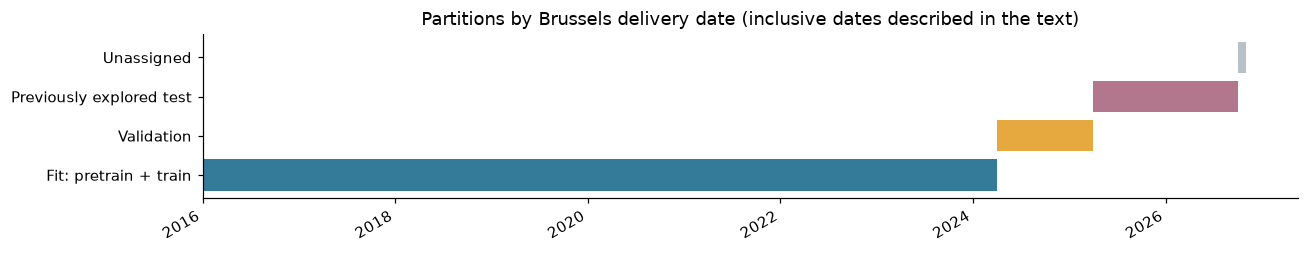

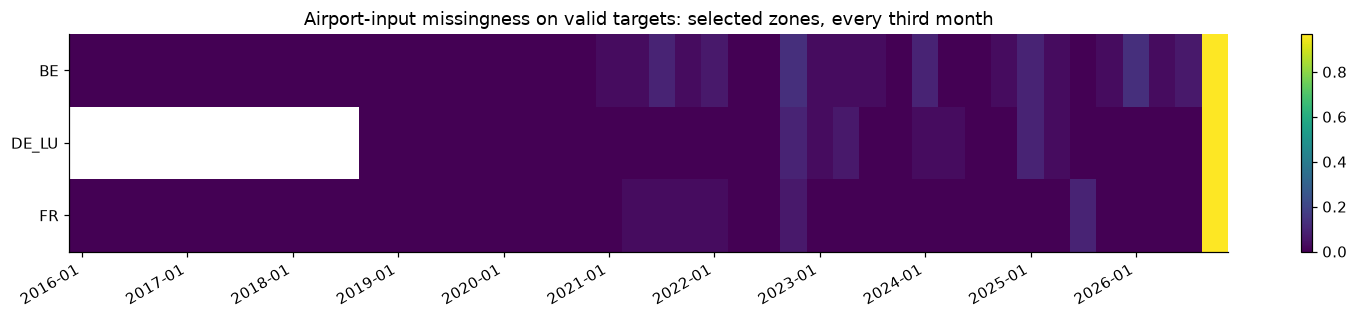

,rows,target_hours,latest_available_target_hours,history_available_target_hours
split,,,,
fit,3543190,3050470,2844023,2851368
test,644448,634578,561552,564959
unassigned,36505,35736,1008,1032
val,429240,428427,373632,376584


In [3]:
fig, ax = plt.subplots(figsize=(12, 2.4))
for label, start, end, color in [
    ("Fit: pretrain + train", "2016-01-01", "2024-04-01", "#347a99"),
    ("Validation", "2024-04-01", "2025-04-01", "#e5a940"),
    ("Previously explored test", "2025-04-01", "2026-10-01", "#b2768d"),
    ("Unassigned", "2026-10-01", "2026-11-01", "#b9c1c8")]:
    ax.barh(label, pd.Timestamp(end) - pd.Timestamp(start), left=pd.Timestamp(start), color=color)
ax.set_title("Partitions by Brussels delivery date (inclusive dates described in the text)")
fig.autofmt_xdate(); plt.tight_layout(); plt.show()
coverage = pd.read_csv(ROOT / "results/airport_temperature_coverage.csv")
selected = coverage[coverage.scored_zone & coverage.zone.isin(ZONES)].copy()
selected["latest_missing_fraction"] = 1 - selected.latest_available_target_hours / selected.target_hours.replace(0, np.nan)
matrix = selected.pivot_table(index="zone", columns="month", values="latest_missing_fraction", aggfunc="mean")
heatmap(matrix.iloc[:, ::3], "Airport-input missingness on valid targets: selected zones, every third month")
plt.show()
display(coverage[coverage.scored_zone].groupby("split")[["rows", "target_hours", "latest_available_target_hours", "history_available_target_hours"]].sum())


hours   mean  variance  standard_deviation  median    IQR
zone  partition                                                            
BE    Fit         72310  81.23   7824.86               88.46   49.71  56.30
      Validation   8760  80.89   2494.35               49.94   83.82  60.29
DE_LU Fit         48216  95.53  10306.37              101.52   59.39  78.32
      Validation   8760  89.45   3392.97               58.25   90.07  53.06
FR    Fit         72310  84.96   9657.73               98.27   49.98  56.24
      Validation   8760  67.10   2383.22               48.82   66.83  77.97

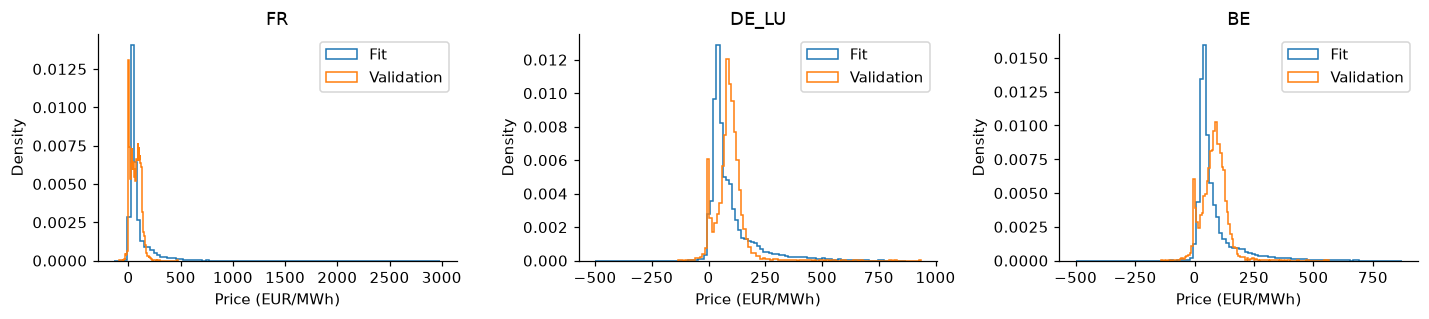

In [4]:
# Training/validation variability only. Read just selected zones and columns.
master = ROOT / "staging/forecast_dataset_v1.0/current/nodes"
if LOAD_LOCAL_DETAILS and master.exists():
    if len(ZONES) > 5:
        raise ValueError("Use at most five zones for bounded distribution inspection")
    filt = ds.field("zone").isin(ZONES) & ds.field("split").isin(["pretrain", "train", "val"])
    prices = ds.dataset(master).to_table(columns=["zone", "split", "price"], filter=filt).to_pandas()
    prices["partition"] = np.where(prices.split.eq("val"), "Validation", "Fit")
    stats = prices.groupby(["zone", "partition"]).price.agg(hours="count", mean="mean", variance="var", standard_deviation="std", median="median")
    stats["IQR"] = prices.groupby(["zone", "partition"]).price.quantile(.75) - prices.groupby(["zone", "partition"]).price.quantile(.25)
    display(stats.round(2))
    fig, axes = plt.subplots(1, len(ZONES), figsize=(13, 3), squeeze=False)
    for ax, zone in zip(axes[0], ZONES):
        for label, group in prices[prices.zone.eq(zone)].groupby("partition"):
            ax.hist(group.price.dropna(), bins=100, histtype="step", density=True, label=label)
        ax.set(title=zone, xlabel="Price (EUR/MWh)", ylabel="Density"); ax.legend()
    plt.tight_layout(); plt.show()
else:
    display(Markdown("Local variability panel is optional. Enable LOAD_LOCAL_DETAILS with the pinned local dataset present; no test-target distribution is produced."))


**Reading the data:** coverage is not the same as volatility. The missingness panel retains structural absences; standard deviation and IQR describe finite fit/validation prices. Variance is in (EUR/MWh)². These distributions explain differing difficulty, not which model to select on test.

## 2. What did we train, and what changed?

We have **seven forecasting setups**: weekly persistence; per-zone and pooled XGBoost; pooled MLP; GAT; GRU+MLP; GRU+GAT. The two five-seed studies contain **27 distinct variant names across 145 experiment jobs**. A per-zone XGBoost job fits 49 market models. Two price-only baselines were repeated across studies; they are not ten independent seeds.

Current models learn **asinh(price/50)** with L1 loss and invert with **50·sinh(prediction)** before price scoring. This preserves negative and zero prices and compresses extremes. Transformed-space L1 is not the same objective as MAE in EUR/MWh. Neural imputation and standardization use training data only.

**Main story:** recent-price baselines, controlled feature/topology comparisons, and airport observations. **Keep as negative evidence:** the specified GRUs. **Historical context:** earlier raw-price versus asinh/L1, France pipeline diagnostics, partner reproduction and the first single-seed suite. **Not scientific results:** smoke fits. CNEC/heterogeneous-graph YAMLs are scaffolds, not completed experiments. JAO constraints here are flat summary features, not extra graph nodes.


,jobs
study,
airport,45
controlled,100


study,variant,model,features,graph,seeds,jobs
airport,gat_airport_history_real,gat,airport_history,real,5,5
airport,gat_airport_latest_real,gat,airport_latest,real,5,5
airport,gat_recent_real,gat,recent,real,5,5
airport,mlp_airport_history_none,mlp,airport_history,none,5,5
airport,mlp_airport_latest_none,mlp,airport_latest,none,5,5
airport,mlp_recent_none,mlp,recent,none,5,5
airport,pooled_xgb_airport_history_none,pooled_xgb,airport_history,none,5,5
airport,pooled_xgb_airport_latest_none,pooled_xgb,airport_latest,none,5,5
airport,pooled_xgb_recent_none,pooled_xgb,recent,none,5,5
controlled,gat_jao_real,gat,jao,real,5,5


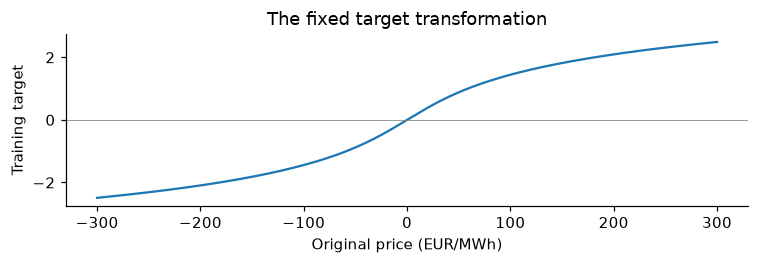

In [5]:
inventory = report.inventory()
assert inventory.jobs.sum() == 145 and inventory.variant.nunique() == 27
display(inventory.groupby("study")[["jobs"]].sum())
display(HTML("<details><summary>Full 29-row study inventory (two repeated names)</summary>" + inventory.to_html(index=False) + "</details>"))
fig, ax = plt.subplots(figsize=(7, 2.5))
p = np.linspace(-300, 300, 400)
ax.plot(p, np.arcsinh(p / 50)); ax.set(xlabel="Original price (EUR/MWh)", ylabel="Training target", title="The fixed target transformation"); ax.axhline(0, color="grey", linewidth=.5)
plt.tight_layout(); plt.show()


## 3. Which baselines are competitive?

The headline comparison holds recent-price/calendar inputs fixed. The per-zone tree comes from the controlled study; pooled trees, MLP and GAT use the airport study's price-only controls. They share the dataset, partitions and seeds.

The main chart uses **the same valid target hours with finite weekly history**, so persistence is comparable. The table separately retains all-target MAE/RMSE. No weather-complete-case filtering is applied. Error bars show sample SD over five training seeds; persistence is deterministic. They are not forecast prediction intervals.


Exact full validation/test target-key, value and mask signatures match across all four learned headline models.

,model,split,matched_MAE,seed_SD,all_target_MAE,all_target_RMSE,matched_hours,all_target_hours
0,Per-zone XGBoost,val,21.2580,0.0416,21.2542,39.4022,428213,428427
1,Pooled XGBoost,val,20.8421,0.0088,20.8406,38.0009,428213,428427
2,MLP,val,21.4864,0.1124,21.4859,57.6457,428213,428427
3,GAT,val,21.1468,0.0884,21.1416,69.1661,428213,428427
4,Weekly persistence,val,30.1822,0.0000,NaN,NaN,428213,428427
5,Per-zone XGBoost,test,21.8689,0.0417,21.8668,39.8388,633885,634578
6,Pooled XGBoost,test,21.4360,0.0106,21.4299,43.5951,633885,634578
7,MLP,test,21.2540,0.0809,21.2507,35.9355,633885,634578
8,GAT,test,20.9900,0.0755,20.9838,35.3302,633885,634578
9,Weekly persistence,test,29.1334,0.0000,NaN,NaN,633885,634578


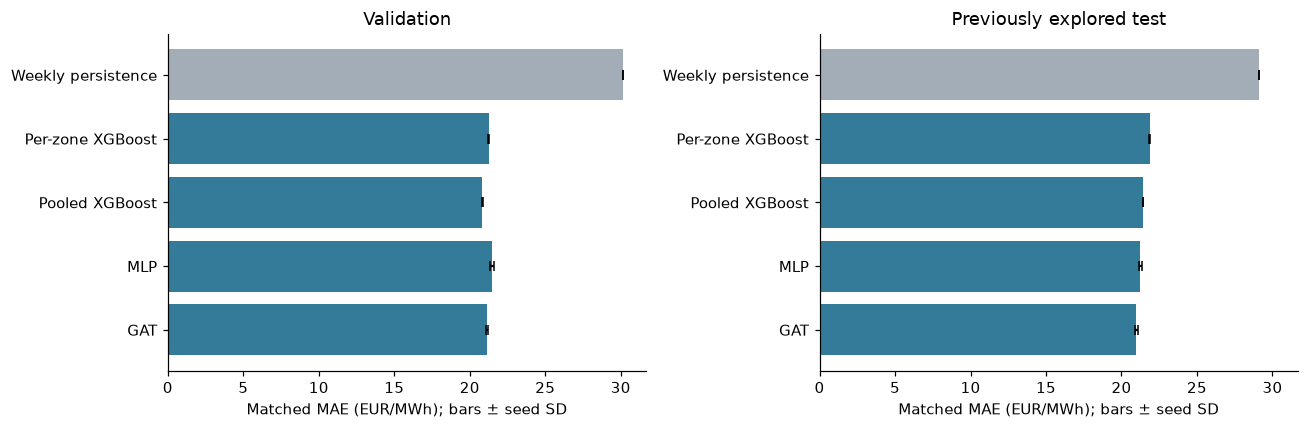

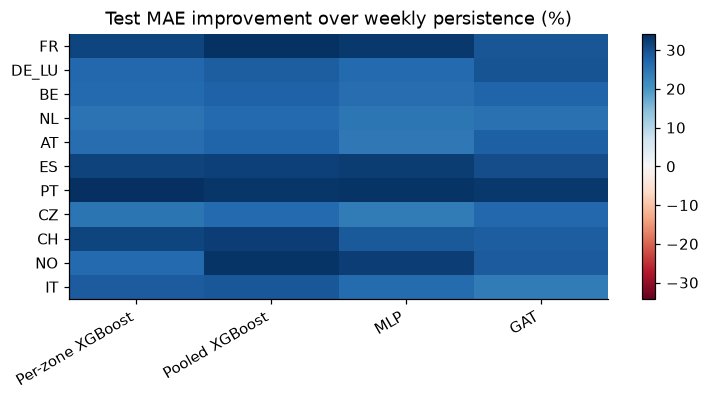

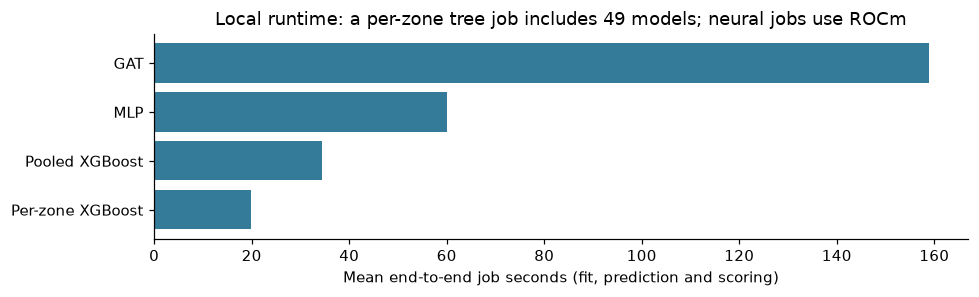

In [6]:
display(Markdown(report.compare_signatures()))
main = report.main_table()
display(main.drop(columns="job_seconds").round(4))
report.main_figure(); plt.show()
report.country_figure(COUNTRIES); plt.show()
fig, ax = plt.subplots(figsize=(9, 2.8))
f = main[main.split.eq("val") & main.job_seconds.notna()]
ax.barh(f.model, f.job_seconds, color="#347a99")
ax.set(xlabel="Mean end-to-end job seconds (fit, prediction and scoring)", title="Local runtime: a per-zone tree job includes 49 models; neural jobs use ROCm")
plt.tight_layout(); plt.show()


**Interpretation:** pooling is a major control: a graph should be compared with pooled classical models, not only independent country trees. Country improvements vary, and France is an important counterexample. Country/market scores pool errors over target hours; prices are never averaged into a national target.

## 4. What do graphs, additional features and histories contribute?

The next panels use the original five-seed controlled study. **All richer-input panels are retrospective/conditional:** equal inputs do not guarantee that operational rankings survive removal of unavailable inputs.

The rich features include load forecasts, four ERA5-lineage variables and flat JAO summaries. Self-loop and degree-preserving shuffled GATs hold the architecture fixed. Three rewiring seeds are shown separately across the same five training seeds; they are not 15 independent training seeds. We have no matching price-only self-loop/shuffled experiment.


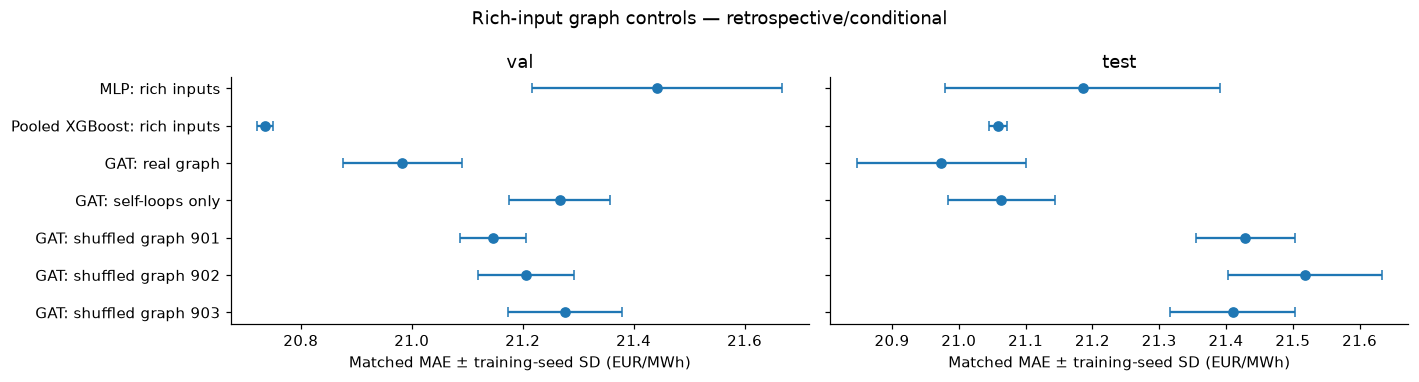

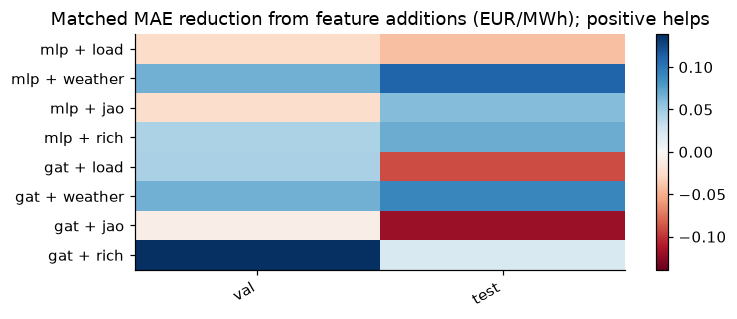

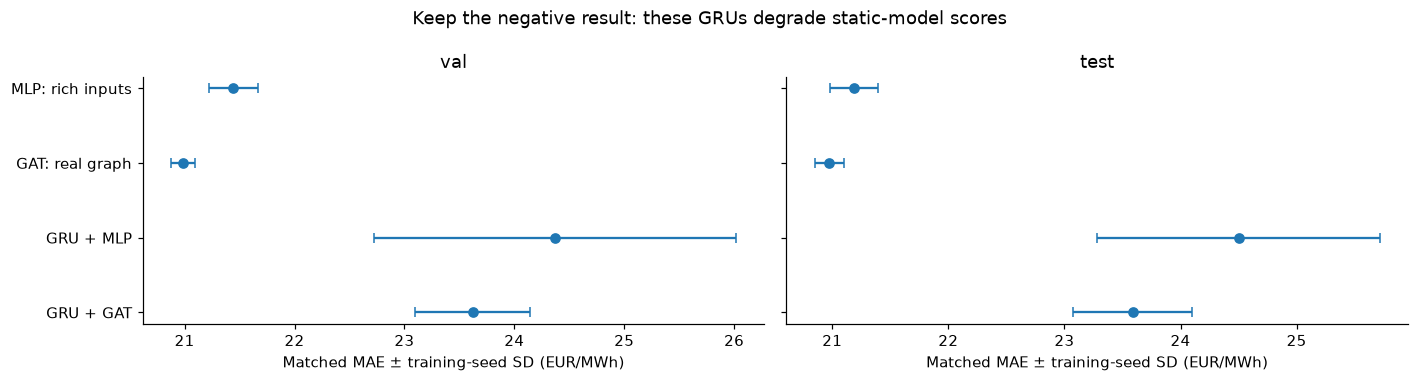

,contrast,improvement,lower,upper
0,mlp_rich_none_to_gat_rich_real,0.4599,0.2004,0.8605
1,gat_rich_self_to_gat_rich_real,0.2838,0.1300,0.4601
2,gru_mlp_rich_none_to_gru_gat_rich_real,0.7501,0.5567,0.9432
3,gat_rich_shuffled_rewire901_to_gat_rich_real,0.1637,-0.0401,0.3348
4,gat_rich_shuffled_rewire902_to_gat_rich_real,0.2237,0.0529,0.3829
5,gat_rich_shuffled_rewire903_to_gat_rich_real,0.2931,0.1451,0.4497
6,mlp_recent_none_to_mlp_rich_none,0.0435,-0.3047,0.2566
7,gat_recent_real_to_gat_rich_real,0.1388,0.0143,0.2681


In [7]:
report.family_figure(["mlp_rich_none", "pooled_xgb_rich_none", "gat_rich_real", "gat_rich_self", "gat_rich_shuffled_rewire901", "gat_rich_shuffled_rewire902", "gat_rich_shuffled_rewire903"], "Rich-input graph controls — retrospective/conditional")
plt.show()
ablations = []
for model, graph in [("mlp", "none"), ("gat", "real")]:
    for group in ["load", "weather", "jao", "rich"]:
        ablations.append({"addition": model + " + " + group, **{split: report.score("controlled", f"{model}_recent_{graph}", split).paired_mae_mean - report.score("controlled", f"{model}_{group}_{graph}", split).paired_mae_mean for split in ["val", "test"]}})
heatmap(pd.DataFrame(ablations).set_index("addition"), "Matched MAE reduction from feature additions (EUR/MWh); positive helps", center=True)
plt.show()
report.family_figure(["mlp_rich_none", "gat_rich_real", "gru_mlp_rich_none", "gru_gat_rich_real"], "Keep the negative result: these GRUs degrade static-model scores")
plt.show()
intervals = report.summaries["controlled"]["validation_intervals"]
display(pd.DataFrame([{ "contrast": key, "improvement": value["mean_mae_improvement"], "lower": value["ci95_lower"], "upper": value["ci95_upper"]} for key, value in intervals.items() if "rich" in key]).round(4))


**Interpretation:** rich real GAT improves on MLP and self-loop controls overall, but one shuffled-control validation interval spans zero. The tested GRUs are worse; this does not rule out temporal learning generally. Validation-week intervals resample shared weeks across countries, condition on fixed fitted models and are unadjusted for multiple comparisons. Feature additions are mixed; do not choose the weather-only GAT retrospectively because it has the smallest old test MAE.

## 5. Did current airport observations help?

For each country we froze its largest airport by 2023 passenger traffic. Regional zones share that proxy. At D−1 noon, latest temperature must be at least two and at most six hours old; history uses the preceding 24-hour window ending two hours before origin and requires 18 hourly samples for a mean. Inputs are constant across delivery day D.

These are actual airport reports rather than retrospective ERA5, but **historical receipt/revision timestamps remain unavailable**. The two-hour buffer is an assumption, so the experiment remains conditional. ERA5, airport observations and the earlier perfect-weather oracle are different experiments, not interchangeable weather products.


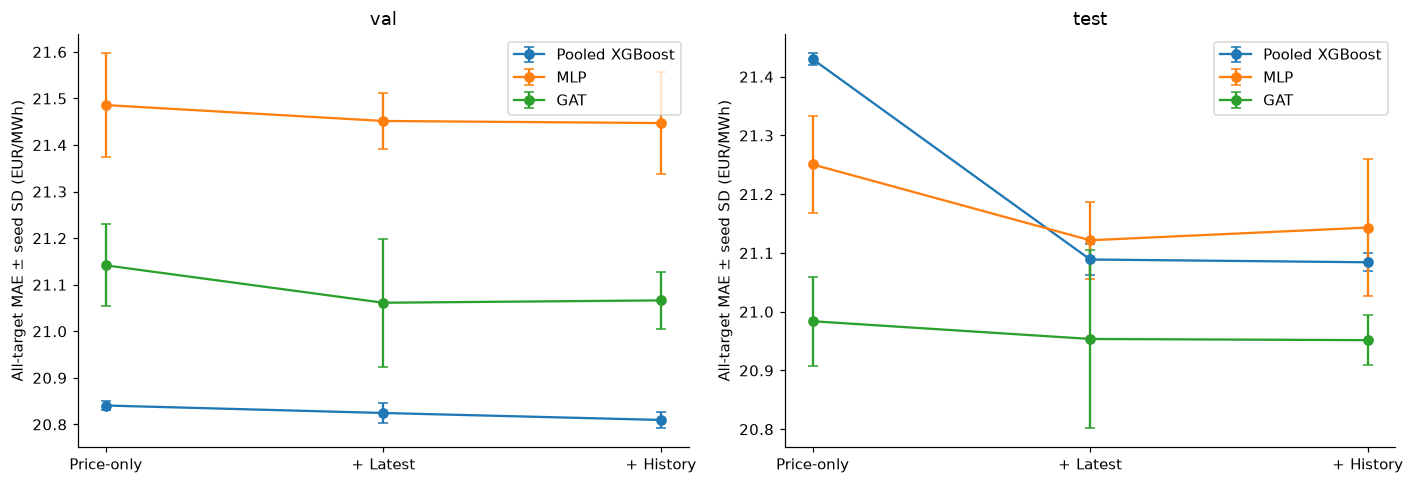

subgroup,airport_mapped,airport_unmapped,all
variant,,,
gat_airport_history_real,20.9253,21.1661,20.9516
gat_airport_latest_real,20.9280,21.1626,20.9536
gat_recent_real,20.9365,21.3700,20.9838
mlp_airport_history_none,21.1153,21.3712,21.1432
mlp_airport_latest_none,21.1000,21.2985,21.1216
mlp_recent_none,21.1845,21.7908,21.2507
pooled_xgb_airport_history_none,20.7284,23.9882,21.0841
pooled_xgb_airport_latest_none,20.7375,23.9568,21.0889
pooled_xgb_recent_none,20.7837,26.7047,21.4299


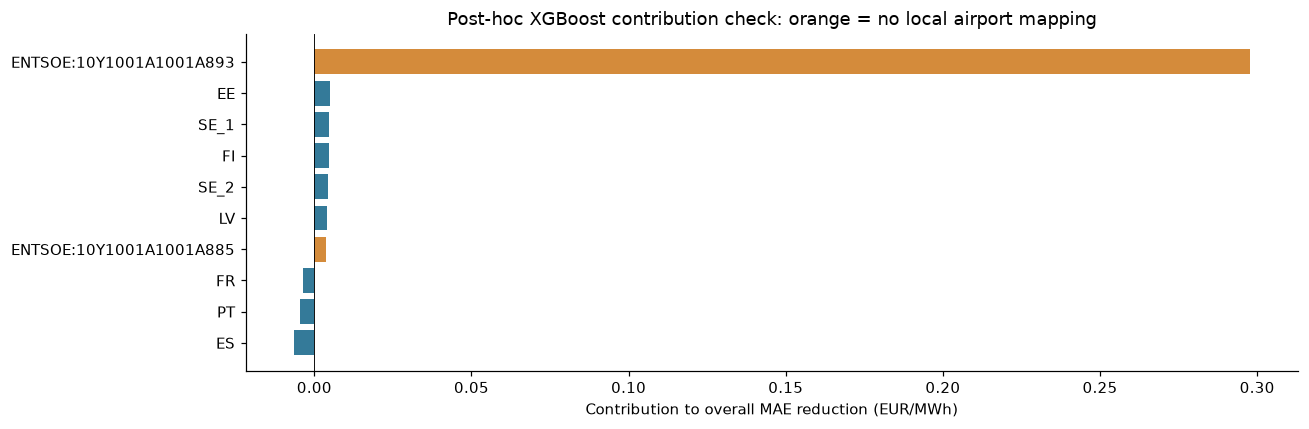

**87.3% of XGBoost's headline test improvement comes from `ENTSOE:10Y1001A1001A893`, whose local temperature inputs are all missing.** Adding features changes the jointly fitted pooled model; this is not evidence of a local temperature signal. GAT can also transmit weather information from mapped neighbours.

In [8]:
report.weather_figure(); plt.show()
subgroups = pd.read_csv(ROOT / "results/airport_temperature_full_geographic_subgroups.csv")
display(subgroups[subgroups.split.eq("test")].pivot(index="variant", columns="subgroup", values="mae_mean").round(4))
contributions = pd.read_csv(ROOT / "results/airport_temperature_full_market_contributions.csv")
f = contributions[contributions.split.eq("test") & contributions.model.eq("pooled_xgb") & contributions.features.eq("airport_latest")].copy()
f = f.loc[f.contribution_to_overall_mae.abs().nlargest(10).index].sort_values("contribution_to_overall_mae")
fig, ax = plt.subplots(figsize=(12, 4))
ax.barh(f.zone, f.contribution_to_overall_mae, color=np.where(f.airport_mapped, "#347a99", "#d48b3b"))
ax.axvline(0, color="black", linewidth=.6); ax.set(xlabel="Contribution to overall MAE reduction (EUR/MWh)", title="Post-hoc XGBoost contribution check: orange = no local airport mapping")
plt.tight_layout(); plt.show()
review = report.root / "results/airport_temperature_full_review.json"
import json
review = json.loads(review.read_text())
display(Markdown(f"**{review['share_of_overall_improvement']:.1%} of XGBoost's headline test improvement comes from `{review['largest_xgb_latest_test_contributor']}`, whose local temperature inputs are all missing.** Adding features changes the jointly fitted pooled model; this is not evidence of a local temperature signal. GAT can also transmit weather information from mapped neighbours."))


**Interpretation:** gains are small and inconsistent on markets with airport coverage. France worsens for all three models; Germany/Luxembourg shows small latest-temperature gains. Validation intervals include zero for most weather additions. These airport proxies cannot answer whether regional heatwaves or proper temperature forecasts would help. The mapped/unmapped contribution check is post-hoc description, not a changed evaluation cohort.

## 6. Investigate a country and week

The next panels use the selectors at the top. The default week is fixed in advance, not chosen for a large error. Seed 224 is illustrative, not the best test seed. Full-series metrics above use all five seeds. Detailed target exploration is limited to validation and at most 31 days; no target gaps are filled.


### FR — Aligned validation-only window; no missing targets filled.

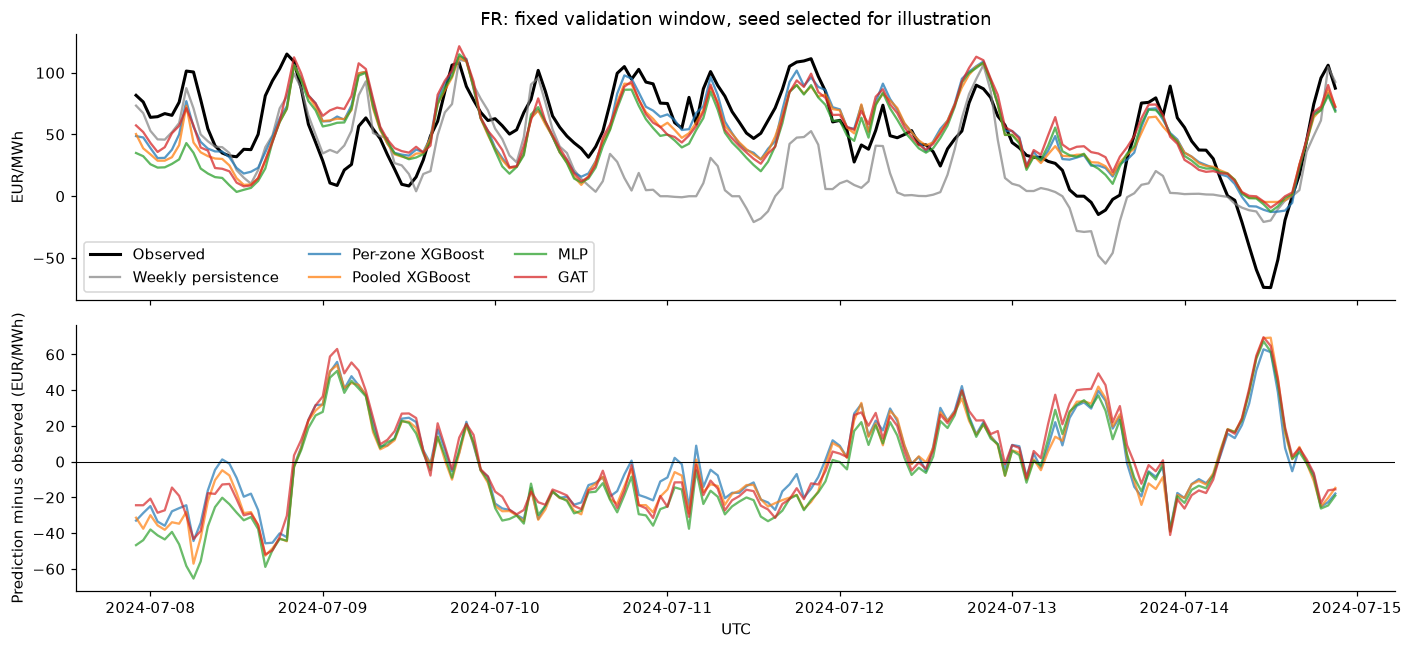

/tmp/ipykernel_369613/3825428295.py:9: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(weather.round(2))


,delivery_date,origin_utc,temperature_C,age_h,mean24_C,hours_present
0,2024-07-08,2024-07-07 10:00:00+00:00,16.0,2.0,16.379999,24.0
1,2024-07-09,2024-07-08 10:00:00+00:00,20.0,2.0,17.920000,24.0
2,2024-07-10,2024-07-09 10:00:00+00:00,25.0,2.0,21.500000,24.0
3,2024-07-11,2024-07-10 10:00:00+00:00,21.0,2.0,21.650000,23.0
4,2024-07-12,2024-07-11 10:00:00+00:00,19.0,2.0,20.879999,24.0
5,2024-07-13,2024-07-12 10:00:00+00:00,14.0,2.0,18.950001,22.0
6,2024-07-14,2024-07-13 10:00:00+00:00,16.0,2.0,15.480000,23.0


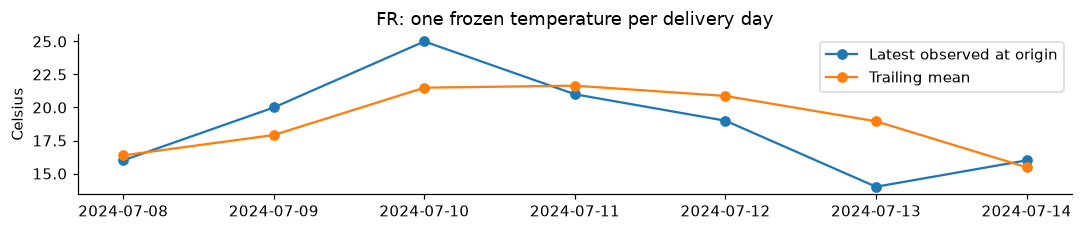

### DE_LU — Aligned validation-only window; no missing targets filled.

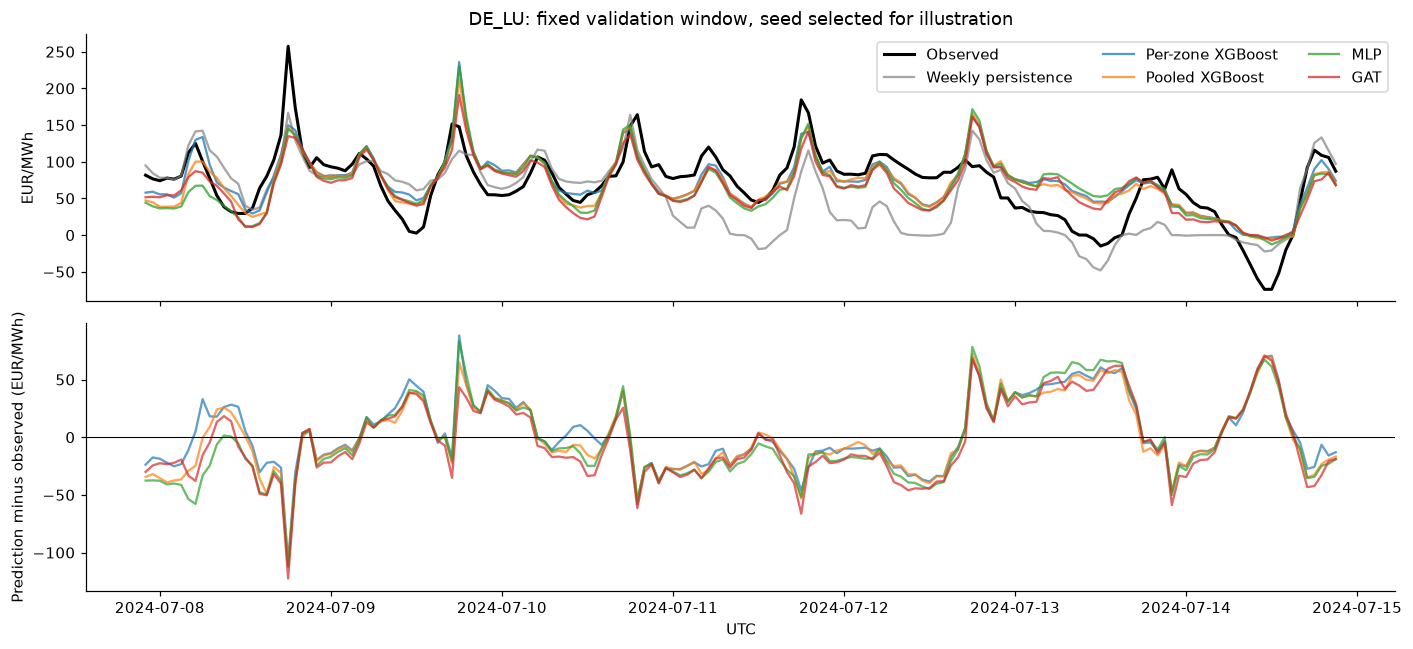

/tmp/ipykernel_369613/3825428295.py:9: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(weather.round(2))


,delivery_date,origin_utc,temperature_C,age_h,mean24_C,hours_present
0,2024-07-08,2024-07-07 10:00:00+00:00,17.0,2.17,17.389999,23.0
1,2024-07-09,2024-07-08 10:00:00+00:00,20.0,2.17,16.959999,23.0
2,2024-07-10,2024-07-09 10:00:00+00:00,24.0,2.17,22.120001,24.0
3,2024-07-11,2024-07-10 10:00:00+00:00,24.0,2.17,25.830000,24.0
4,2024-07-12,2024-07-11 10:00:00+00:00,23.0,2.17,22.170000,24.0
5,2024-07-13,2024-07-12 10:00:00+00:00,23.0,2.17,23.120001,24.0
6,2024-07-14,2024-07-13 10:00:00+00:00,18.0,2.17,19.750000,24.0


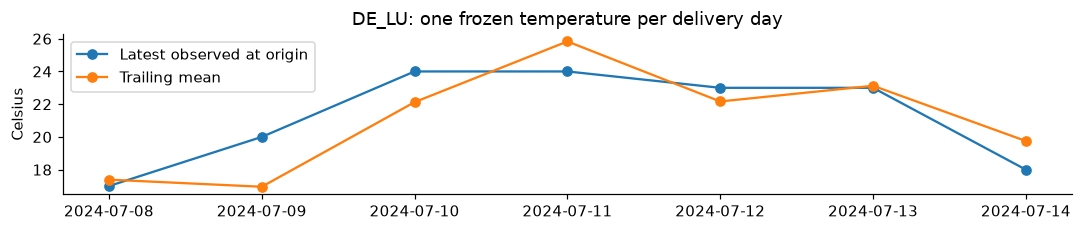

### BE — Aligned validation-only window; no missing targets filled.

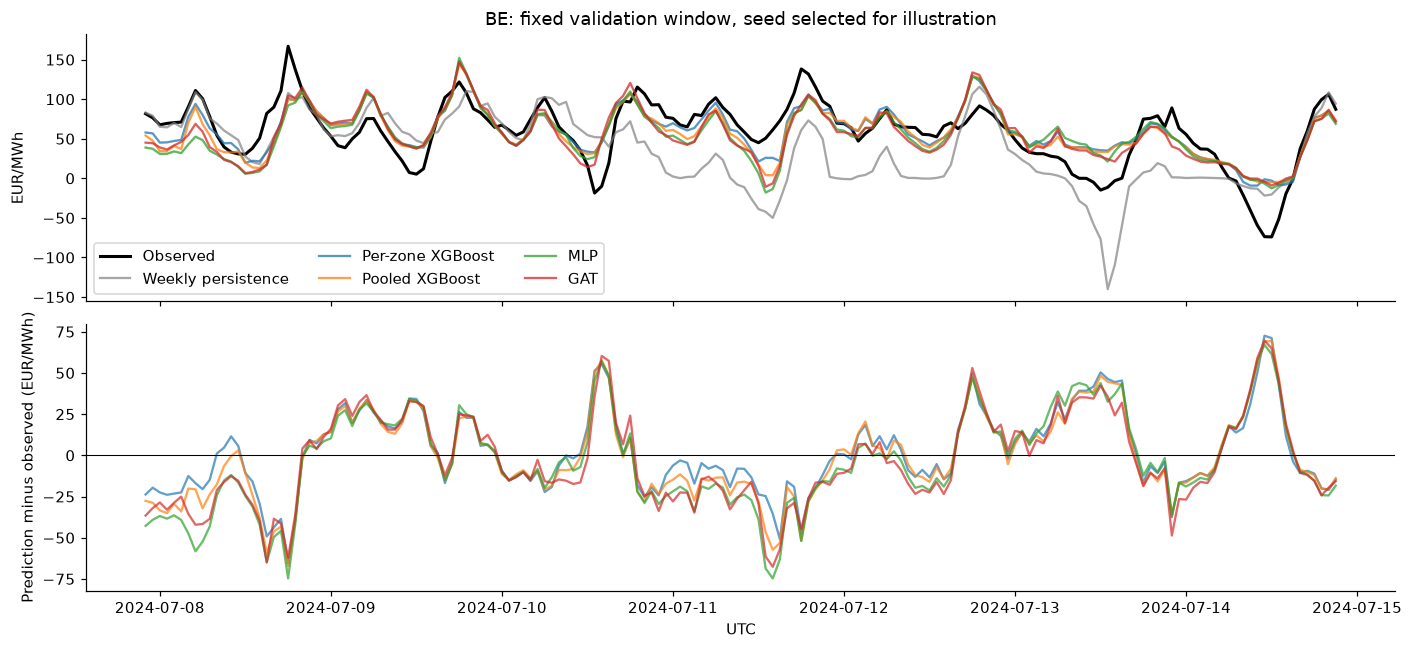

/tmp/ipykernel_369613/3825428295.py:9: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(weather.round(2))


,delivery_date,origin_utc,temperature_C,age_h,mean24_C,hours_present
0,2024-07-08,2024-07-07 10:00:00+00:00,16.0,2.17,15.180000,22.0
1,2024-07-09,2024-07-08 10:00:00+00:00,18.0,2.17,15.830000,24.0
2,2024-07-10,2024-07-09 10:00:00+00:00,22.0,2.17,18.330000,24.0
3,2024-07-11,2024-07-10 10:00:00+00:00,20.0,2.17,20.580000,24.0
4,2024-07-12,2024-07-11 10:00:00+00:00,18.0,2.17,18.920000,24.0
5,2024-07-13,2024-07-12 10:00:00+00:00,14.0,2.17,17.360001,22.0
6,2024-07-14,2024-07-13 10:00:00+00:00,14.0,2.17,13.680000,22.0


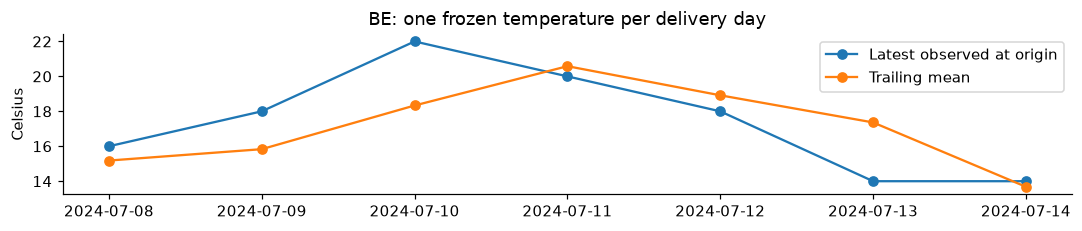

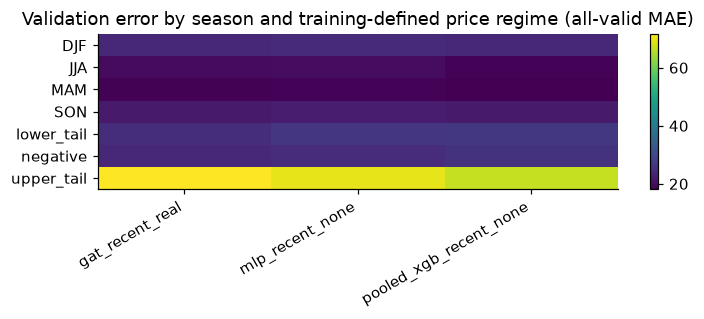

In [9]:
if LOAD_LOCAL_DETAILS:
    for zone in ZONES:
        frame, message = report.drilldown(zone, START, END, SEED, MODELS)
        display(Markdown(f"### {zone} — {message}"))
        if frame is not None:
            plot_window(frame, zone); plt.show()
            weather = report.weather_window(zone, START, END)
            if weather is not None:
                display(weather.round(2))
                fig, ax = plt.subplots(figsize=(10, 2.2))
                ax.plot(weather.delivery_date, weather.temperature_C, marker="o", label="Latest observed at origin")
                ax.plot(weather.delivery_date, weather.mean24_C, marker="o", label="Trailing mean")
                ax.set(ylabel="Celsius", title=f"{zone}: one frozen temperature per delivery day"); ax.legend()
                plt.tight_layout(); plt.show()
            else:
                display(Markdown("Pinned local airport cache unavailable; temperature timeline omitted."))
else:
    display(Markdown("Summary mode: enable LOAD_LOCAL_DETAILS for bounded local prediction and temperature timelines."))
regimes = pd.read_csv(ROOT / "results/airport_temperature_full_regimes.csv")
f = regimes[regimes.scope.eq("overall") & regimes.split.eq("val") & regimes.variant.isin(["mlp_recent_none", "gat_recent_real", "pooled_xgb_recent_none"]) & regimes["slice"].isin(["DJF", "MAM", "JJA", "SON", "negative", "lower_tail", "upper_tail"])]
heatmap(f.pivot(index="slice", columns="variant", values="mae_mean"), "Validation error by season and training-defined price regime (all-valid MAE)")
plt.show()


**Reading the investigations:** residuals show timing and magnitude errors; compare the same timestamps across models. Error on negative-price and tail slices is a descriptive diagnostic. Tail thresholds come from training only, and the slices overlap. Temperature values above are features from the pinned cache, not future delivery-day weather. Observation age and history coverage make stale/missing data visible.

## 7. What can we conclude?

| Question | What this evidence supports | What remains open |
|---|---|---|
| Do learned methods beat weekly persistence? | Recent-price models improve the matched aggregate substantially | Performance varies by market and regime |
| Does pooling matter? | Pooled XGBoost is a necessary strong reference | Isolating geography/identity effects needs dedicated controls |
| Do graphs add value? | Modest overall GAT gains over matched MLP; rich topology controls offer additional evidence | Price-only topology controls, operational availability and country counterexamples |
| Does temperature help? | Small mixed gains for the airport experiment | Regional representativeness, receipt vintages and archived weather forecasts |
| Did temporal histories help? | These GRU variants were worse | Other temporal settings or architectures were not tested |
| Were constraints graph nodes? | No: tested JAO summaries were flat node features | Detailed CNEC graph identities and models remain untested |

**Retain all archived runs.** Use the matched baselines in the main narrative; retain rich conditional studies and negative results with their limitations. No best seed or new model is selected from test performance here.

### Appendix A. Earlier pipeline development

The earlier experiments answer narrower questions on different populations. In the fixed-learner France sequence, adding the prior-day auction price was a much larger improvement than changing the target transformation alone. The ten-country comparison changed **both transformation and loss**. Partner reproduction uses legacy geography/filled inputs and a different cohort; it is not another row in the 49-market ranking.


In [10]:
diagnostics = json.loads((ROOT / "results/pipeline_diagnostics_france.json").read_text())
display(pd.DataFrame(diagnostics["rows"])[["profile", "split", "mae", "rmse", "hours"]].round(3))
transform = pd.read_csv(ROOT / "results/c1_xgb_countries_asinh_l1_comparison.csv")
display(transform[transform.split.eq("test")][["zone", "xgb_mae_raw_mse", "xgb_mae_asinh_l1", "persistence_mae_asinh_l1"]].round(3))


,profile,split,mae,rmse,hours
0,weekly_flags,val,34.669,43.670,8760
1,weekly_flags,test,36.318,45.849,13152
2,weekly_calendar,val,31.551,40.921,8760
3,weekly_calendar,test,32.092,42.125,13152
4,recent_price,val,20.387,27.181,8760
5,recent_price,test,22.199,31.159,13152
6,load,val,20.390,26.964,8760
7,load,test,22.212,30.938,13152
8,flows,val,20.471,27.039,8760
9,flows,test,22.139,30.819,13152


,zone,xgb_mae_raw_mse,xgb_mae_asinh_l1,persistence_mae_asinh_l1
1,BE,30.409,30.013,31.118
3,FR,35.615,34.826,32.443
5,NL,30.874,30.676,31.037
7,DE_LU,32.717,32.338,33.910
9,AT,27.413,26.235,27.245
11,ES,29.334,26.824,25.770
13,PT,28.513,26.569,25.978
15,PL,30.790,30.514,33.240
17,CZ,28.895,28.603,29.400
19,CH,21.371,21.514,21.325


### Appendix B. Context, not additional multi-seed evidence

- The original five-model single-seed suite is preserved in `results/vibing_suite_full.json`; its baseline implementations/sampler history differ from later repeats.
- The partner's reproduced score uses 43 scored zones; compare within its own protocol.
- The old France “current temperature” diagnostic was retrospective ERA5. Its perfect delivery-hour weather companion deliberately supplies future information and is an **oracle**, not a deployable candidate or a guaranteed performance bound.
- Smoke fits and unimplemented heterogeneous-graph configuration files are excluded from scientific comparisons.

### Appendix C. Provenance and reproducibility

The main evidence is the verified 100-job controlled study and 45-job airport study. The table below pins their fingerprints. The reporting helpers recompute aggregate errors from seed/zone summaries; local detail panels additionally check identical target keys/values/masks. When local Parquets are absent the summaries still execute and unavailable detail is stated explicitly.

For deeper source auditing see `docs/leakage_audit.md`, `docs/controlled_study_comparison.md`, `docs/airport_temperature_results.md` and the existing dataset inspection notebook. Repeated test inspection and unresolved source publication vintages limit the claims throughout.


In [11]:
display(pd.DataFrame(report.sources))
assert "torch" not in sys.modules and "xgboost" not in sys.modules
plt.close("all")
print("Completed: verified summaries, CPU-only execution, no training or downloads.")


,study,fingerprint,summary_sha256,jobs
0,controlled,fd19205863b9d81b0f5d46535d9c970579838565b4b782...,006a9ddb603e80f0b06f5f8d699087262308d5449a8e4d...,100
1,airport,8be91e76858aa68c606def353b59030b5b96c6ef94904d...,8312e05431465d4d22f4297ea9c4e67b11d5125f8353a7...,45


Completed: verified summaries, CPU-only execution, no training or downloads.


### Appendix D. Learning behaviour and the first single-seed suite

These learning curves use illustrative seed 224. They show validation MAE in transformed target units, not EUR/MWh. Early stopping uses validation only. The old single-seed results below provide historical context; do not pool them with the five-seed means above.


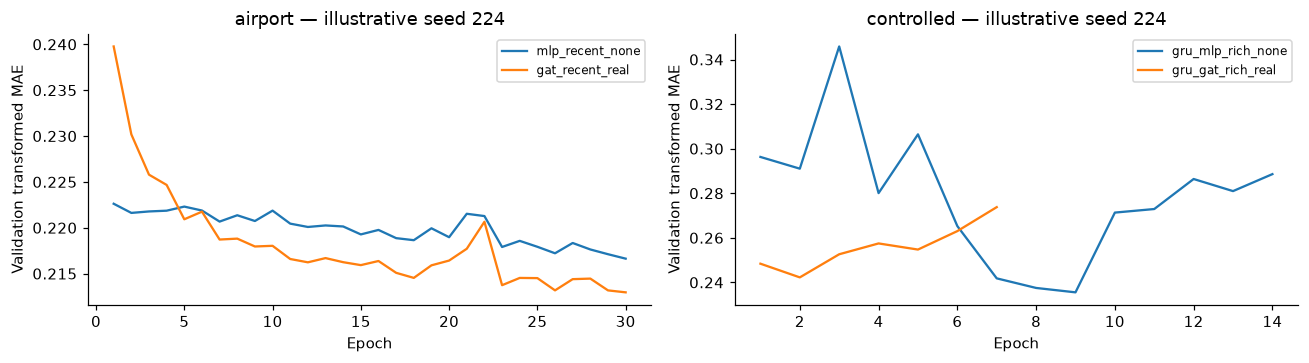

,experiment,split,paired_hours,paired_mae
0,neighbour_xgb,test,633885,21.8724
2,neighbour_xgb,val,428213,20.8312
4,real_gat,test,633885,20.8279
6,real_gat,val,428213,20.8074
8,recent_xgb,test,633885,21.8654
10,recent_xgb,val,428213,21.1839
12,rich_xgb,test,633885,22.1323
14,rich_xgb,val,428213,21.2751
16,shuffled_gat,test,633885,21.5421
18,shuffled_gat,val,428213,21.2261


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, study, variants in [
    (axes[0], "airport", ["mlp_recent_none", "gat_recent_real"]),
    (axes[1], "controlled", ["gru_mlp_rich_none", "gru_gat_rich_real"])]:
    for variant in variants:
        job = next(j for j in report.summaries[study]["jobs"] if j["variant"] == variant and j["job"]["seed"] == 224)
        curve = pd.DataFrame(job["details"]["learning_curve"])
        ax.plot(curve.epoch, curve.val_transformed_mae, label=variant)
    ax.set(xlabel="Epoch", ylabel="Validation transformed MAE", title=study + " — illustrative seed 224"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
old = pd.DataFrame(json.loads((ROOT / "results/vibing_suite_full.json").read_text())["aggregate"])
display(old[old.scope.eq("overall") & old.coverage.eq("all")][["experiment", "split", "paired_hours", "paired_mae"]].round(4))
plt.close("all")
